<a href="https://colab.research.google.com/github/gmauricio-toledo/math-ML/blob/main/Notebooks/24-ModelosFundacionales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CLIP: Contrastive Language-Image Pre-training

<h4>Texto e Imágenes en el mismo espacio latente</h4>

[CLIP](https://huggingface.co/docs/transformers/model_doc/clip) entrena simultáneamente dos redes neuronales independientes —un codificador visual (ResNet o *Vision Transformer*) y un codificador de texto (Transformer)— para proyectar imágenes y descripciones al mismo espacio vectorial $\mathbb{R}^{512}$ normalizado, es decir, sobre la hiperesfera unitaria $S^{511}$. Utilizando 400 millones de pares `(imagen, texto)` organizados en lotes de tamaño $N$, el modelo optimiza una pérdida contrastiva simétrica (*InfoNCE*) que maximiza el producto interior $\langle u_i, v_i \rangle$ de los pares correspondientes en la diagonal de la matriz de similitudes, mientras minimiza la similitud de los $N^2 - N$ pares cruzados incorrectos.

Al sustituir las etiquetas fijas por esta geometría métrica en $S^{511}$, CLIP logra clasificar imágenes en categorías arbitrarias nunca vistas durante su entrenamiento (*zero-shot*). En inferencia, basta proyectar una imagen para obtener su vector $I$, proyectar $K$ descripciones textuales candidatas para obtener $T_1, \dots, T_K$, y asignar la clase que maximice la similitud coseno $I \cdot T_k$ (reescalada antes de aplicar $\text{Softmax}$), sintetizando así un clasificador lineal al vuelo a partir de lenguaje natural.

In [ ]:
!gdown --folder 15PQxgn-MJHy9f_NLEj7z2_vboKV3lf-Y

Retrieving folder contents
Processing file 1lNRKNA7QXaKuES_qeBBSgKB3oIaz6SzN 2016-09-20 22.28.44.jpg
Processing file 1mHJzDoFufdBOOykVr03CQIvf4ayBb1sd 2024-10-03 22.10.51.jpg
Processing file 1Hi8pXzH8yq-qgNyZonsdLYCm3y37Alkf 2026-10-18 20.36.43.jpg
Processing file 1KktUmioD266QkvTwn5zf8B4WQeH0P7x7 2026-10-19 11.43.18.jpg
Processing file 1HBVEjNKlGc3Gy0VjvKrecTV3-2gIstjP 2026-10-19 14.16.56.jpg
Processing file 1wmaoiiFP812Aore5i6wA-tAQSkND_asA 2026-10-24 14.03.46.jpg
Processing file 1hoc-PEDS2PoCXwZLDQg0hMp2Yq9ZGQJt 2026-10-24 14.03.48.jpg
Processing file 1ZmqOhfZA-oEzgg4bHiXas6_8hbvvJH97 2026-10-24 16.39.43.jpg
Processing file 1wkE5Jq-aRJ5M-yCDlInFrW-FAKpgwsgX 2026-10-24 17.05.42.jpg
Processing file 1AQ3cNnnkaQz09x1XwSdg8oVfgLpsFSB8 2026-10-25 08.38.51.jpg
Processing file 1ZpgVWdLOE7e6NiNgR0ZVQA0eoq-wTOWz 2026-10-25 12.36.38.jpg
Processing file 1L7Rn9EwbWm81J8L10bJDSYCmEJKIFvBz 2026-11-14 08.33.06.jpg
Processing file 161W63QSHJQkCcHizhoYxOqMRnpo_4D_y 2026-11-15 15.34.54.jpg
Processing 

In [ ]:
#@title Cargar CLIP y comparar embeddings

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
import os
import glob

# 1. Cargar modelo y procesador (ejecutar antes de entrar a clase)
device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(model_id).to(device)
processor = CLIPProcessor.from_pretrained(model_id)
model.eval()

def evaluar_clip(ruta_imagen: str, etiquetas: list[str], temperatura: float = 100.0):
    """
    Proyecta una imagen y N textos a la hiperesfera S^511,
    calcula el producto interior y aplica Softmax escalado.
    """
    imagen = Image.open(ruta_imagen).convert("RGB")

    inputs = processor(
        text=etiquetas,
        images=imagen,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        # Extraer vectores latentes en R^512 y normalizar a norma L2 = 1 (esfera S^511)
        img_emb = outputs.image_embeds
        img_emb = img_emb / img_emb.norm(p=2, dim=-1, keepdim=True)

        txt_emb = outputs.text_embeds
        txt_emb = txt_emb / txt_emb.norm(p=2, dim=-1, keepdim=True)

        # Producto interior <v_img, v_txt> (similitud coseno pura en [-1, 1])
        similitud_coseno = (img_emb @ txt_emb.T).squeeze(0)

        # CLIP usa un factor de escala logit_scale antes de Softmax
        escala = model.logit_scale.exp() if temperatura is None else temperatura
        logits = similitud_coseno * escala
        probs = torch.softmax(logits, dim=-1)

    cos_np = similitud_coseno.cpu().numpy()
    probs_np = probs.cpu().numpy()

    # Visualización lado a lado: Imagen + Geometría (coseno vs Softmax)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})

    axes[0].imshow(imagen)
    axes[0].axis("off")
    axes[0].set_title("Imagen de entrada", fontsize=12, fontweight="bold")

    y_pos = np.arange(len(etiquetas))
    bars = axes[1].barh(y_pos, probs_np * 100, color="#092d71", alpha=0.88)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(etiquetas, fontsize=10)
    axes[1].invert_yaxis()
    axes[1].set_xlim(0, 115)
    axes[1].set_xlabel("Probabilidad Softmax (%)", fontsize=10)
    axes[1].set_title(f"Similitud en $S^{{511}}$ (escala = {float(escala):.1f})", fontsize=12, fontweight="bold")
    axes[1].grid(axis="x", linestyle="--", alpha=0.4)

    # Anotar tanto la probabilidad como el producto interior real <u, v>
    for bar, p, c in zip(bars, probs_np, cos_np):
        axes[1].text(
            bar.get_width() + 1.5,
            bar.get_y() + bar.get_height() / 2,
            f"{p*100:.1f}%  (cos = {c:.3f})",
            va="center",
            fontsize=9.5
        )

    plt.tight_layout()
    plt.show()


def a_tensor(salida):
    """Extrae el tensor proyectado sin importar la versión de transformers."""
    if isinstance(salida, torch.Tensor):
        return salida
    if hasattr(salida, "pooler_output") and salida.pooler_output is not None:
        return salida.pooler_output
    return salida[0]

def buscar_fotos(change):
    consulta = change["new"].strip()
    if not consulta:
        return

    with salida:
        clear_output(wait=True)
        with torch.no_grad():
            txt_inputs = processor(text=[consulta], return_tensors="pt", padding=True).to(device)
            T = a_tensor(model.get_text_features(**txt_inputs))
            T = T / T.norm(p=2, dim=-1, keepdim=True)

            # Producto interior <I_k, T> en [-1, 1]
            similitudes = (E_img @ T.T).squeeze(-1).cpu().numpy()

        top3_idx = np.argsort(similitudes)[::-1][:3]

        fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
        fig.suptitle(f'Top-3 resultados para: "{consulta}"', fontsize=12, fontweight="bold")

        for rank, (ax, idx) in enumerate(zip(axes, top3_idx), start=1):
            ax.imshow(imagenes[idx])
            ax.set_title(f"#{rank}  |  cos = {similitudes[idx]:.3f}", fontsize=10, color="#092d71")
            ax.axis("off")

        plt.tight_layout()
        plt.show()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [ ]:
# --- Ejemplo de prueba en vivo ---
# Tip: CLIP fue entrenado principalmente en inglés, aunque entiende palabras sueltas en español.
# Para máxima precisión en vivo, traduce las propuestas de los alumnos al inglés (o usa ambos).
etiquetas = [
    "a mathematics lecture at a university",
    "a rock concert with bright lights",
    "a photo of a cute dog",
    "a photo of a black dog",
    "a blackboard full of equations",
    "an empty coffee cup on a desk"
]

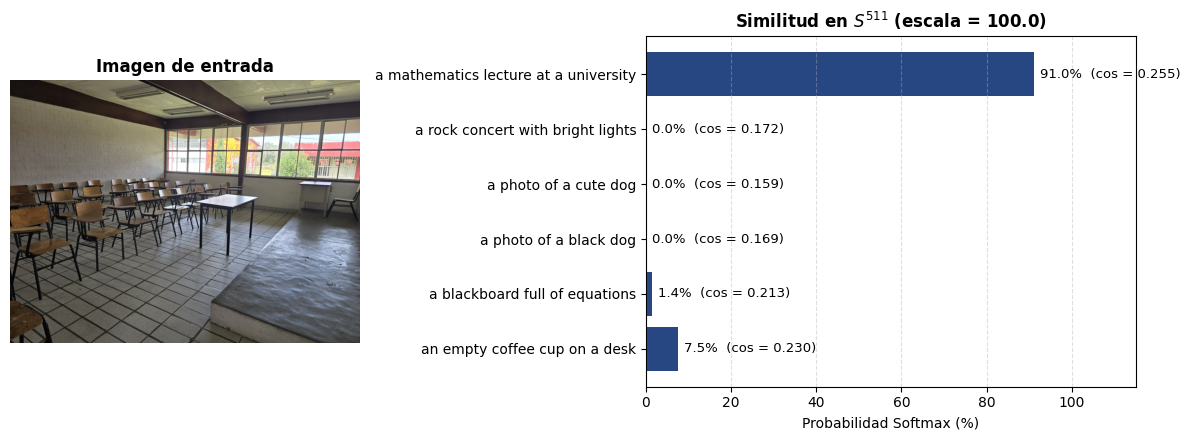

In [ ]:
import os

img_path = "2026-10-19 11.43.18.jpg"
# img_path = "2026-10-24 14.03.48.jpg"
# img_path = "2024-10-03 22.10.51.jpg"
# img_path = "2016-09-20 22.28.44.jpg"

img_path = os.path.join("imagenes_indexar", img_path)

evaluar_clip(img_path, etiquetas, temperatura=None)

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# 2. Cargar colección de imágenes desde una carpeta local
CARPETA_FOTOS = "imagenes_indexar"
rutas = sorted(glob.glob(os.path.join(CARPETA_FOTOS, "*.*")))
imagenes = [Image.open(r).convert("RGB") for r in rutas if r.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))]

# 3. Indexación asíncrona: Precalculamos la matriz E_img de tamaño (M, 512) normalizada
with torch.no_grad():
    img_inputs = processor(images=imagenes, return_tensors="pt").to(device)
    E_img = a_tensor(model.get_image_features(**img_inputs))
    E_img = E_img / E_img.norm(p=2, dim=-1, keepdim=True)

print(f"Índice listo: {len(imagenes)} imágenes proyectadas en el espacio latente.")

# 4. Interfaz interactiva: cuadro de texto + cuadrícula 1x3
caja_busqueda = widgets.Text(
    value="a cute animal",
    placeholder="Escribe tu búsqueda y presiona Enter...",
    description="Buscar:",
    continuous_update=False,
    layout=widgets.Layout(width="65%")
)
salida = widgets.Output()


caja_busqueda.observe(buscar_fotos, names="value")

display(caja_busqueda, salida)
buscar_fotos({"new": caja_busqueda.value})

Índice listo: 15 imágenes proyectadas en el espacio latente.


Text(value='a cute animal', continuous_update=False, description='Buscar:', layout=Layout(width='65%'), placeh…

Output()

## BERT Finetuning

In [ ]:
!gdown 1tiAinSvVhQ337kwbvM3dmaSqxVwAVc7b

Downloading...
From (original): https://drive.google.com/uc?id=1tiAinSvVhQ337kwbvM3dmaSqxVwAVc7b
From (redirected): https://drive.google.com/uc?id=1tiAinSvVhQ337kwbvM3dmaSqxVwAVc7b&confirm=t&uuid=b803307b-15e9-4269-a668-441a712a9afe
To: /content/daraair-emotion - roberta-large_finetuned.zip
100% 1.28G/1.28G [00:33<00:00, 38.0MB/s]


In [ ]:
import zipfile
import os

zip_path = "/content/daraair-emotion - roberta-large_finetuned.zip"
extract_path = "/content/modelo"

if os.path.exists(zip_path):
    print(f"Descomprimiendo {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Descompresión completada")
else:
    print(f"El archivo {zip_path} no fue encontrado.")

Descomprimiendo /content/daraair-emotion - roberta-large_finetuned.zip...
Descompresión completada


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Cargar modelo entrenado desde disco
RUTA_MODELO = "/content/modelo"
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(RUTA_MODELO)
model = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO).to(device)
model.eval()

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, b

In [ ]:
etiquetas = [model.config.id2label[i] for i in range(model.config.num_labels)]
colores = ["#3b82f6", "#eab308", "#ec4899", "#ef4444", "#8b5cf6", "#10b981"]

# 2. Widgets interactivos: actualización en cada pulsación de tecla (continuous_update=True)
caja_texto = widgets.Text(
    value="I thought I failed the topology exam, until I saw my grade",
    placeholder="Escribe palabra por palabra en inglés...",
    description="Texto:",
    continuous_update=True,
    layout=widgets.Layout(width="80%")
)

slider_temp = widgets.FloatSlider(
    value=1.0,
    min=0.1,
    max=3.0,
    step=0.1,
    description="Temp (T):",
    continuous_update=True,
    layout=widgets.Layout(width="45%")
)

# Botones rápidos con frases de prueba para la clase (incluyendo un caso OOD)
ejemplos = {
    "Giro emocional": "I thought I failed the topology exam, until I saw my grade",
    "Mensaje positivo": "I feel fine today, it's a good day",
    "OOD (Teorema)": "Let G be a finitely generated discrete subgroup of PSL(2, C)",
    "OOD (Ruido)": "blue triangle Tuesday integral matrix"
}
botones_ejemplo = [widgets.Button(description=k, layout=widgets.Layout(width="auto")) for k in ejemplos]
for btn in botones_ejemplo:
    btn.on_click(lambda b: setattr(caja_texto, "value", ejemplos[b.description]))

salida = widgets.Output()

def actualizar_grafica(*args):
    texto = caja_texto.value.strip()
    T = slider_temp.value

    with salida:
        clear_output(wait=True)
        if not texto:
            print("Escribe algo arriba para ver las predicciones")
            return

        inputs = tokenizer(texto, return_tensors="pt", truncation=True, max_length=128).to(device)
        with torch.no_grad():
            logits = model(**inputs).logits.squeeze(0)
            probs = torch.softmax(logits / T, dim=-1).cpu().numpy()
            logits_np = logits.cpu().numpy()

        ganadora = etiquetas[np.argmax(probs)]

        fig, ax = plt.subplots(figsize=(9.5, 3.6))
        y_pos = np.arange(len(etiquetas))
        bars = ax.barh(y_pos, probs * 100, color=colores, alpha=0.9, height=0.6)

        ax.set_yticks(y_pos)
        ax.set_yticklabels([e.upper() for e in etiquetas], fontsize=10.5, fontweight="bold")
        ax.invert_yaxis()
        ax.set_xlim(0, 118)
        ax.set_xlabel("Probabilidad Softmax (%)", fontsize=10)
        ax.set_title(
            f"Predicción: {ganadora.upper()}  (T = {T:.1f})",
            fontsize=11.5,
            fontweight="bold",
            color="#092d71"
        )
        ax.grid(axis="x", linestyle="--", alpha=0.4)

        for bar, p, z in zip(bars, probs, logits_np):
            ax.text(
                bar.get_width() + 1.5,
                bar.get_y() + bar.get_height() / 2,
                f"{p*100:5.1f}%",
                va="center",
                fontsize=9.5
            )

        plt.tight_layout()
        plt.show()

caja_texto.observe(actualizar_grafica, names="value")
slider_temp.observe(actualizar_grafica, names="value")

display(widgets.HBox(botones_ejemplo), caja_texto, slider_temp, salida)
actualizar_grafica()

Text(value='I thought I failed the topology exam, until I saw my grade', description='Texto:', layout=Layout(w…

FloatSlider(value=1.0, description='Temp (T):', layout=Layout(width='45%'), max=3.0, min=0.1)

Output()

El finetuning se hizo muy similar a esto:

In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

# 1. Cargar corpus (16,000 textos cortos en 6 clases: sadness, joy, love, anger, fear, surprise)
dataset = load_dataset("dair-ai/emotion")
etiquetas = dataset["train"].features["label"].names

# 2. Tokenizar texto -> tensores de IDs y máscaras de atención
MODEL_ID = "roberta-large"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def tokenizar(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=64)

ds_tokenizado = dataset.map(tokenizar, batched=True)

# 3. Cargar modelo preentrenado + capa lineal nueva de 6 salidas
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(etiquetas),
    id2label={i: nombre for i, nombre in enumerate(etiquetas)},
    label2id={nombre: i for i, nombre in enumerate(etiquetas)},
)

# 4. Entrenamiento estándar (optimizador AdamW + CrossEntropyLoss internos)
args = TrainingArguments(
    output_dir="./checkpoints_emotion",
    num_train_epochs=3,
    per_device_train_batch_size=32,
    learning_rate=2e-5,
    eval_strategy="epoch",
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_tokenizado["train"],
    eval_dataset=ds_tokenizado["validation"],
)

trainer.train()

# 5. Guardar modelo ajustado y tokenizador para inferencia
trainer.save_model("./modelo_emotion_final")
tokenizer.save_pretrained("./modelo_emotion_final")

## LLM inference

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Descargados 13 artículos de Wikipedia.
✓ Bernhard Riemann (1826) -> 1 instituciones
✓ Johann Carl Friedrich Gauss (1777) -> 2 instituciones
✓ David Hilbert (1862) -> 1 instituciones
✓ Dennis Parnell Sullivan (1941) -> 2 instituciones
✓ Amalie Emmy Noether (1882) -> 4 instituciones
✓ Felix Klein (1849) -> 1 instituciones
✓ Henri Poincaré (1854) -> 6 instituciones
✓ Hermann Weyl (1885) -> 1 instituciones
✓ John Milnor (1931) -> 1 instituciones
✓ John von Neumann (1903) -> 6 instituciones
✓ Mikhail Gromov (1943) -> 1 instituciones
✓ Terrence Tao (1975) -> 2 instituciones
✓ William Thurston (1946) -> 3 instituciones


,nombre,anio_nacimiento,nacionalidad,areas_principales
0,Bernhard Riemann,1826,Alemán,"[Análisis real, Teoría de números, Geometría d..."
1,Johann Carl Friedrich Gauss,1777,Alemán,"[mathematics, astronomy, geodesy, physics]"
2,David Hilbert,1862,Alemán,"[teoría de invariantes, calculus de variacione..."
3,Dennis Parnell Sullivan,1941,American,"[algebraic topology, geometric topology, dynam..."
4,Amalie Emmy Noether,1882,Alemán,"[Álgebra, Matemática de la física, Teoría de i..."
5,Felix Klein,1849,Alemán,"[Teoría de grupos, Análisis complejo, Geometrí..."
6,Henri Poincaré,1854,Francés,"[Matemáticas, Física teórica, Ciencias celesti..."
7,Hermann Weyl,1885,Alemán,"[Differential geometry, Lie group theory, Repr..."
8,John Milnor,1931,American,"[differential topology, algebraic K-theory, lo..."
9,John von Neumann,1903,Hungarian,"[matemáticas, física, economía, informática, e..."


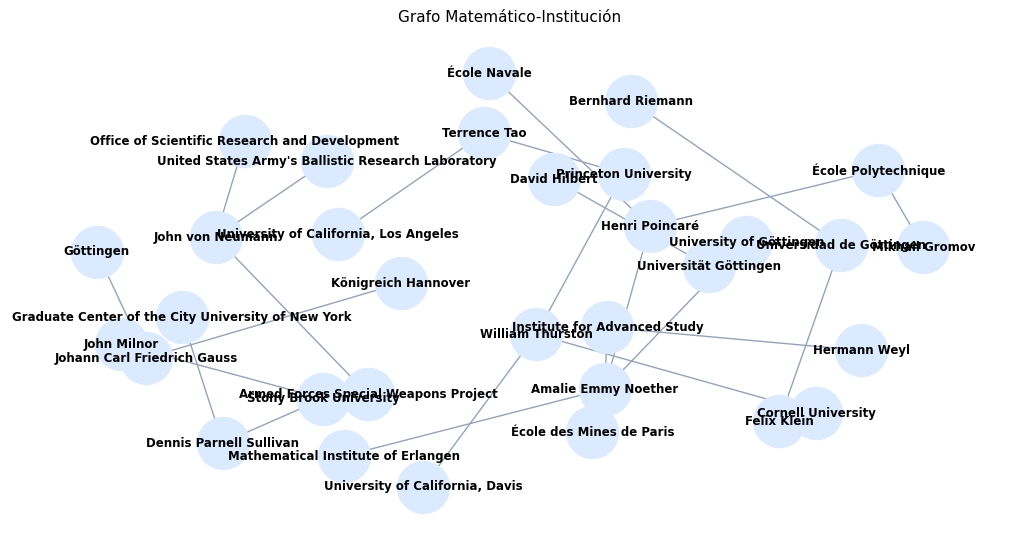

In [ ]:
import re
import json
import requests
import torch
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from typing import List, Optional
from pydantic import BaseModel, Field
from transformers import AutoTokenizer, AutoModelForCausalLM

# 1. Cargar Qwen 2.5 local en memoria (ejecutar antes de iniciar la clase)
# Si tienes >= 20 GB de VRAM puedes subir a "Qwen/Qwen2.5-7B-Instruct"
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    device_map="auto"
)
model.eval()

# 2. Descargar 10 artículos de Wikipedia en una sola petición HTTP
titulos = [
    "Carl_Friedrich_Gauss", "Bernhard_Riemann", "Felix_Klein",
    "David_Hilbert", "Emmy_Noether", "Henri_Poincaré",
    "Hermann_Weyl", "John_von_Neumann", "William_Thurston", "Mikhail_Gromov",
    "Terrence Tao", "Dennis Sullivan", "John Milnor"
]

url = "https://en.wikipedia.org/w/api.php"
params = {
    "action": "query",
    "format": "json",
    "prop": "extracts",
    "exintro": True,
    "explaintext": True,
    "titles": "|".join(titulos)
}
headers = {"User-Agent": "ClaseMLUnison/1.0 (demo academica)"}
paginas = requests.get(url, params=params, headers=headers).json()["query"]["pages"]
textos = {p["title"]: p["extract"] for p in paginas.values() if "extract" in p}
print(f"Descargados {len(textos)} artículos de Wikipedia.")

# 3. Esquema tipado con Pydantic
class PerfilMatematico(BaseModel):
    nombre: str
    anio_nacimiento: int
    anio_fallecimiento: Optional[int] = Field(None, description="null si sigue con vida")
    nacionalidad: str
    instituciones: List[str]
    mentores_o_influencias: List[str]
    areas_principales: List[str]

esquema_json = json.dumps(PerfilMatematico.model_json_schema(), ensure_ascii=False)

def extraer_perfil(titulo: str, texto: str) -> PerfilMatematico:
    mensajes = [
        {
            "role": "system",
            "content": (
                "Eres un extractor de datos. Devuelve ÚNICAMENTE un objeto JSON válido "
                "que cumpla estrictamente con este esquema JSON Schema, sin texto adicional:\n"
                f"{esquema_json}"
            )
        },
        {
            "role": "user",
            "content": f"Artículo: {titulo}\n\nTexto:\n{texto}"
        }
    ]

    prompt = tokenizer.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([prompt], return_tensors="pt").to(model.device)

    with torch.no_grad():
        salida_ids = model.generate(
            **inputs,
            max_new_tokens=400,
            do_sample=False  # Decodificación greedy (T = 0) para máxima fidelidad
        )

    tokens_nuevos = salida_ids[0][len(inputs.input_ids[0]):]
    respuesta = tokenizer.decode(tokens_nuevos, skip_special_tokens=True).strip()

    # Limpiar posibles bloques ```json ... ``` y validar tipos con Pydantic
    match = re.search(r"\{.*\}", respuesta, re.DOTALL)
    json_limpio = match.group(0) if match else respuesta
    return PerfilMatematico.model_validate_json(json_limpio)

# 4. Procesar los 10 artículos
registros = []
for titulo, texto in textos.items():
    perfil = extraer_perfil(titulo, texto)
    registros.append(perfil.model_dump())
    print(f"✓ {perfil.nombre} ({perfil.anio_nacimiento}) -> {len(perfil.instituciones)} instituciones")

# 5. Pasar a DataFrame y Grafo NetworkX
df = pd.DataFrame(registros)
display(df[["nombre", "anio_nacimiento", "nacionalidad", "areas_principales"]])



In [ ]:
B = nx.Graph()
for r in registros:
    mat = r["nombre"]
    B.add_node(mat, bipartite=0, anio=r.get("anio_nacimiento", 1850))
    for inst_raw in r.get("instituciones", []):
        # inst = normalizar_inst(inst_raw)
        inst = inst_raw
        B.add_node(inst, bipartite=1)
        B.add_edge(mat, inst)

# 3. Ordenar ambas columnas para minimizar el cruce de aristas
# Izquierda: orden cronológico
mats = sorted(
    [n for n, d in B.nodes(data=True) if d["bipartite"] == 0],
    key=lambda n: B.nodes[n]["anio"]
)
pos_y_mat = {m: i for i, m in enumerate(mats)}

# Derecha: heurística del baricentro (promedio de posiciones de sus vecinos)
insts = sorted(
    [n for n, d in B.nodes(data=True) if d["bipartite"] == 1],
    key=lambda inst: np.mean([pos_y_mat[vecino] for vecino in B.neighbors(inst)])
)

# 4. Generar coordenadas bipartitas (equivale a nx.bipartite_layout con orden optimizado)
pos = {}
for i, m in enumerate(reversed(mats)):      # De arriba (más antiguo) hacia abajo
    pos[m] = np.array([0.0, i / max(1, len(mats) - 1)])

for i, inst in enumerate(reversed(insts)):
    pos[inst] = np.array([1.0, i / max(1, len(insts) - 1)])

Reducción de nodos: 26 cadenas crudas -> 23 instituciones canónicas

  'Académie des Sciences'  -->  'Academy of Sciences'
  'Armed Forces Special Weapons Project'  -->  'Arms Special Weapons Project'
  "United States Army's Ballistic Research Laboratory"  -->  'Ballistic Research Laboratory'
  'Graduate Center of the City University of New York'  -->  'City University of New York - Graduate Center'
  'U.S. Department of Defense'  -->  'Department of Defense'
  'Société astronomique de France'  -->  'French Astronomical Society'
  'Société mathématique de France'  -->  'French Mathematical Society'
  'Mathematical Institute of Erlangen'  -->  'Institute of Mathematics, Erlangen'
  'Königreich Hannover'  -->  'Kingdom of Hanover'
  'École Navale'  -->  'Naval School'
  'École Polytechnique'  -->  'Polytechnic School'
  'École des Mines de Paris'  -->  'School of Mines'
  'Göttingen'  -->  'University of Göttingen'
  'Universidad de Göttingen'  -->  'University of Göttingen'
  'Universit

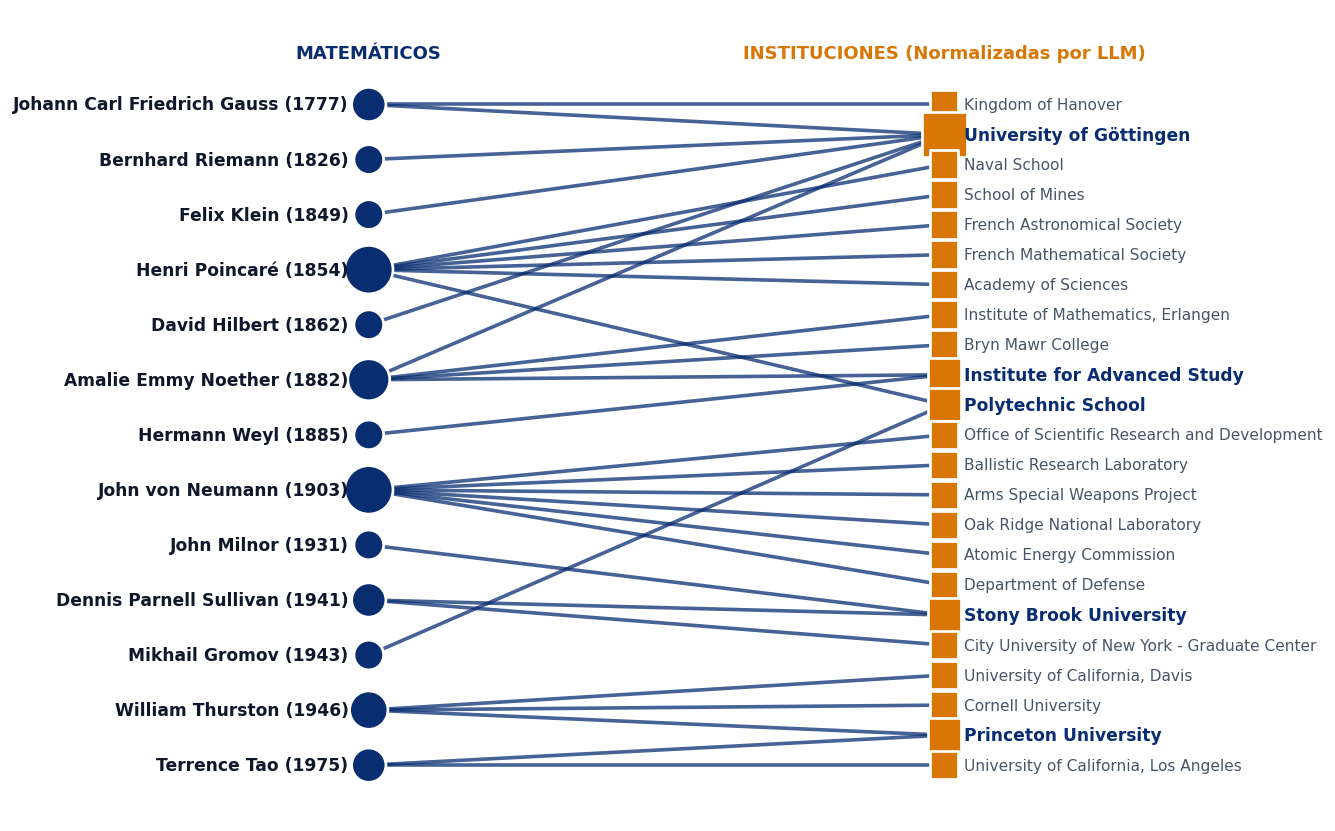

In [ ]:
import re
import json
import torch
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# 1. Recolectar todos los nombres crudos extraídos de Wikipedia
insts_crudas = sorted({
    inst.strip()
    for r in registros
    for inst in r.get("instituciones", [])
    if inst.strip()
})

# 2. Una sola llamada a Qwen con ejemplo explícito llave -> valor
ejemplo_salida = '{"Göttingen": "University of Göttingen", "Georg-August-Universität Göttingen": "University of Göttingen"}'

mensajes = [
    {
        "role": "system",
        "content": (
            "Eres un normalizador de entidades. Mapea cada cadena de la lista a su nombre "
            "canónico corto en inglés. Devuelve ÚNICAMENTE un objeto JSON (diccionario) con "
            f"el formato exacto {ejemplo_salida}, sin listas ni texto extra."
        )
    },
    {
        "role": "user",
        "content": "Normaliza estas cadenas en un solo diccionario JSON:\n" + "\n".join(f"- {x}" for x in insts_crudas)
    }
]

prompt = tokenizer.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
inputs = tokenizer([prompt], return_tensors="pt").to(model.device)

with torch.no_grad():
    salida_ids = model.generate(**inputs, max_new_tokens=600, do_sample=False)

nuevos = salida_ids[0][len(inputs.input_ids[0]):]
respuesta = tokenizer.decode(nuevos, skip_special_tokens=True).strip()

# Extraer JSON y asegurar que sea un dict aunque el modelo devuelva lista de pares
match_dict = re.search(r"\{[^{}]*(?:\{[^{}]*\}[^{}]*)*\}", respuesta, re.DOTALL)
raw_parsed = json.loads(match_dict.group(0) if match_dict else respuesta)

if isinstance(raw_parsed, dict):
    mapa_canonico = raw_parsed
elif isinstance(raw_parsed, list):
    mapa_canonico = {}
    for item in raw_parsed:
        if isinstance(item, dict) and len(item) >= 2:
            vals = list(item.values())
            mapa_canonico[str(vals[0])] = str(vals[1])
else:
    mapa_canonico = {x: x for x in insts_crudas}

print(f"Reducción de nodos: {len(insts_crudas)} cadenas crudas -> {len(set(mapa_canonico.values()))} instituciones canónicas\n")
for crudo, canon in sorted(mapa_canonico.items(), key=lambda x: x[1]):
    if crudo != canon:
        print(f"  {crudo!r}  -->  {canon!r}")

# 3. Construir el grafo bipartito usando el mapa generado por Qwen
B = nx.Graph()
for r in registros:
    mat = r["nombre"]
    B.add_node(mat, bipartite=0, anio=r.get("anio_nacimiento", 1850))
    for inst_raw in r.get("instituciones", []):
        inst = mapa_canonico.get(inst_raw.strip(), inst_raw.strip())
        B.add_node(inst, bipartite=1)
        B.add_edge(mat, inst)

# 4. Ordenar columnas
mats = sorted(
    [n for n, d in B.nodes(data=True) if d["bipartite"] == 0],
    key=lambda n: B.nodes[n]["anio"]
)
pos_y_mat = {m: i for i, m in enumerate(mats)}

insts = sorted(
    [n for n, d in B.nodes(data=True) if d["bipartite"] == 1],
    key=lambda inst: np.mean([pos_y_mat[vecino] for vecino in B.neighbors(inst)])
)

pos = {}
for i, m in enumerate(reversed(mats)):
    pos[m] = np.array([0.0, i / max(1, len(mats) - 1)])
for i, inst in enumerate(reversed(insts)):
    pos[inst] = np.array([1.0, i / max(1, len(insts) - 1)])

# 5. Dibujar el grafo bipartito resultante
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=130)
fig.patch.set_facecolor("#ffffff")

aristas_compartidas = [(u, v) for u, v in B.edges() if B.degree(v) >= 2 or B.degree(u) >= 2]
aristas_unicas = [(u, v) for u, v in B.edges() if (u, v) not in aristas_compartidas]

nx.draw_networkx_edges(B, pos, edgelist=aristas_unicas, edge_color="#cbd5e1", width=1.2, alpha=0.7, ax=ax)
nx.draw_networkx_edges(B, pos, edgelist=aristas_compartidas, edge_color="#092d71", width=2.0, alpha=0.75, ax=ax)

nx.draw_networkx_nodes(
    B, pos, nodelist=mats,
    node_shape="o", node_size=[180 + 90 * B.degree(m) for m in mats],
    node_color="#092d71", edgecolors="white", linewidths=1.5, ax=ax
)
nx.draw_networkx_nodes(
    B, pos, nodelist=insts,
    node_shape="s", node_size=[160 + 90 * B.degree(i) for i in insts],
    node_color="#d97706", edgecolors="white", linewidths=1.5, ax=ax
)

for m in mats:
    x, y = pos[m]
    anio = B.nodes[m]["anio"]
    ax.text(x - 0.035, y, f"{m} ({anio})", ha="right", va="center",
            fontsize=9.5, fontweight="bold", color="#0f172a")

for inst in insts:
    x, y = pos[inst]
    es_hub = B.degree(inst) >= 2
    ax.text(x + 0.035, y, inst, ha="left", va="center",
            fontsize=9.5 if es_hub else 8.5,
            fontweight="bold" if es_hub else "normal",
            color="#092d71" if es_hub else "#475569")

ax.text(0.0, 1.07, "MATEMÁTICOS", ha="center", fontsize=10, fontweight="bold", color="#092d71")
ax.text(1.0, 1.07, "INSTITUCIONES", ha="center", fontsize=10, fontweight="bold", color="#d97706")

ax.set_xlim(-0.55, 1.65)
ax.set_ylim(-0.08, 1.14)
ax.axis("off")
plt.tight_layout()
plt.show()